# IntelliSched AI: data generation, analysis, cleaning and solving

This notebook walks through the pipeline one step at a time. The code lives in the `intellisched` package; `python -m intellisched run` does the same steps from the command line.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import pandas as pd
from IPython.display import Image, display
from intellisched.generate import GenConfig, generate_to_file
from intellisched.workbook import load_workbook
from intellisched import analyze
from intellisched.clean import clean, score_cleaning
from intellisched.solver import solve, verify
pd.set_option('display.width', 160)

## 1. Data generation

A synthetic university sized to fit one term at ~70 % room use and ~80 % teacher load. 3 % of rows are corrupted the way people make data-entry mistakes; the `_Injected` sheet records each one so the cleaner can be scored.

In [2]:
path, _, injected = generate_to_file(GenConfig(seed=1, noise=0.03), '../data/synthetic/notebook_seed1.xlsx')
raw = load_workbook(path)
print({t: len(df) for t, df in raw.items()})
injected.kind.value_counts()

{'Branches': 4, 'Sections': 49, 'Subjects': 190, 'Teachers': 41, 'TeacherPreferences': 184, 'TeacherAvailability': 14, 'TeacherSubjectMap': 293, 'Buildings': 4, 'BuildingTravel': 6, 'Rooms': 21, 'TimeSlots': 36}


kind
strength_out_of_range    4
semester_mismatch        3
load_out_of_range        2
messy_code               2
number_as_text           2
orphan_teacher           2
duplicate_row            2
missing_key              1
Name: count, dtype: int64

## 2. Data analysis

### 2a. Quality of the raw data

In [3]:
quality, log = analyze.quality(raw)
quality

,table,rows,blank_required_cells,to_repair,to_remove,cascade
0,Branches,4,0,0,0,0
1,Sections,49,0,6,0,0
2,Subjects,190,0,1,1,0
3,Teachers,41,0,3,0,0
4,TeacherPreferences,184,0,0,0,0
5,TeacherAvailability,14,0,0,0,0
6,TeacherSubjectMap,293,0,0,6,0
7,Buildings,4,0,0,0,0
8,BuildingTravel,6,0,0,0,0
9,Rooms,21,1,0,1,0


### 2b. Patterns in the data

In [4]:
whole = clean(raw).data
pats = analyze.patterns(whole)
display(pats['hours_by_branch_semester'])
display(pats['subject_mix'])
display(pats['designations'])
pats['assignment_preference']

Semester,1,2,3,4,5,6,7,8
BranchCode,,,,,,,,
CSE,36,32,16,20,19,38,22,22
ECE,22,38,32,36,18,20,19,40
EE,44,38,36,34,22,17,18,42
ME,34,38,40,16,19,28,19,32


,subjects,mean_hours
Type,,
Lab,48,2.000000
Theory,141,3.560284


,teachers,max_load
Designation,,
Assistant Professor,21,20.095238
Associate Professor,12,16.000000
Lecturer,2,20.000000
Professor,4,14.000000
Visiting Faculty,2,10.000000


Priority
not in preferences    107
priority 1             98
priority 3             27
priority 2             25
priority 4             19
priority 5             11
Name: count, dtype: int64

### 2c. Could ALL semesters run at once?

No: the catalog is sized for one term, so teachers and classrooms are over-subscribed. This is why the next step filters to one term.

,check,status,value,limit,note
0,Classroom periods,FAIL,763,576,16 classrooms x 36 slots
1,Lab blocks,PASS,72,72,4 labs x 18 two-period starts a week
2,Section fits a classroom,PASS,0,0,largest classroom seats 90
3,Section fits a lab,WARN,16,0,largest lab seats 60; bigger sections need bat...
4,Every class has a teacher,PASS,0,0,section x subject pairs with no teacher
5,Section weekly hours fit the week,PASS,22,36,busiest section
6,Teachers within weekly load,FAIL,33,0,teachers assigned more hours than their max
7,Teachers have enough free slots,PASS,0,0,hours > slots left after unavailability
8,Travel time for every block pair,PASS,0,0,complete


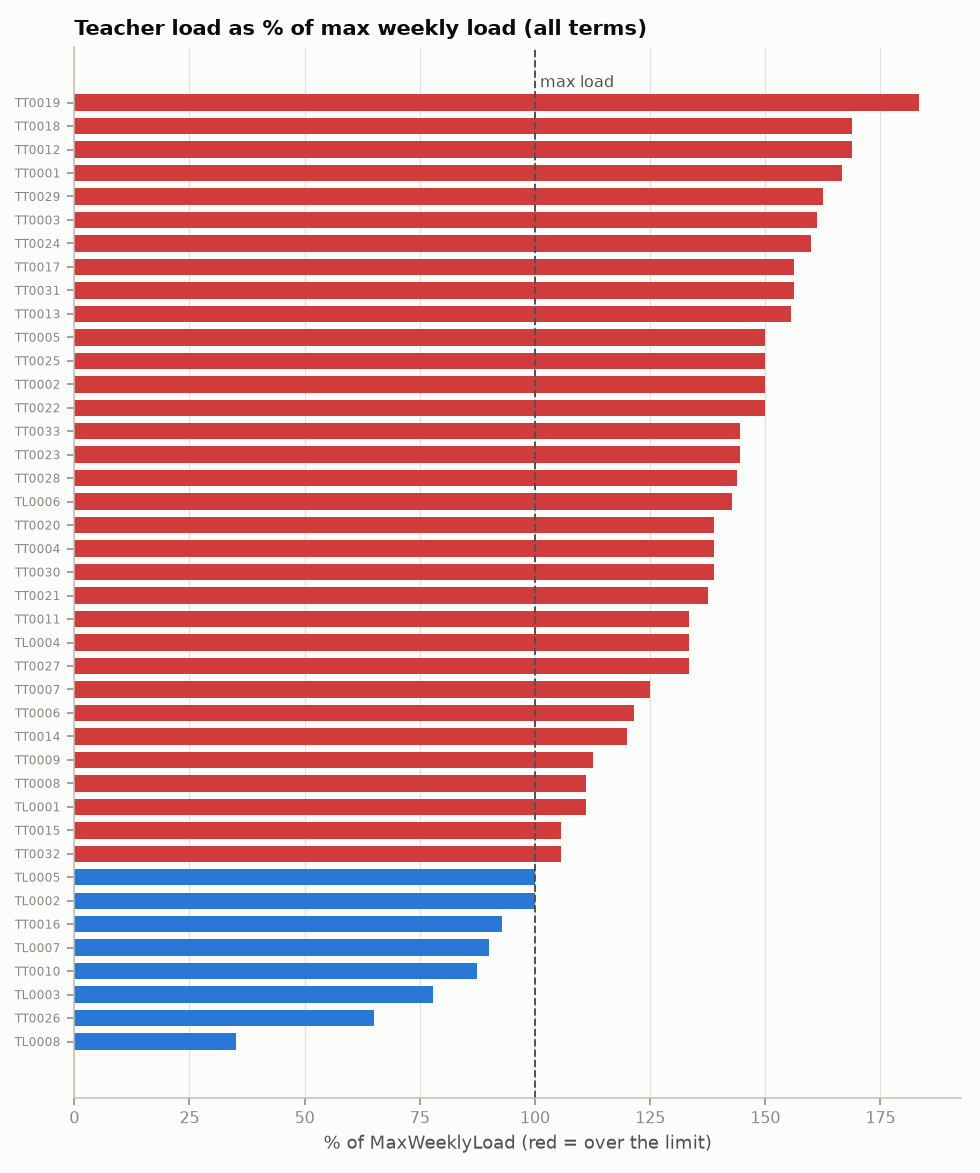

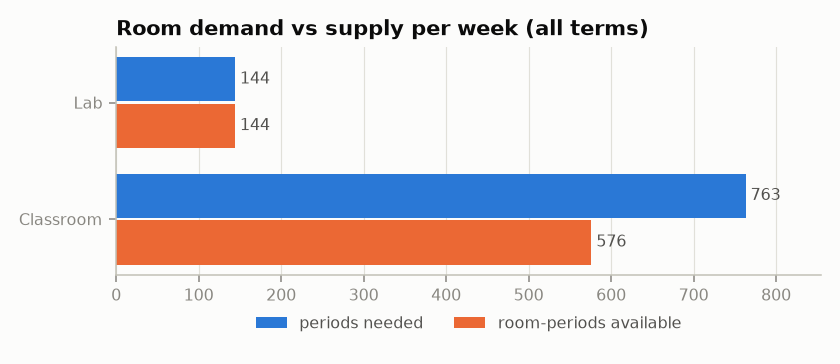

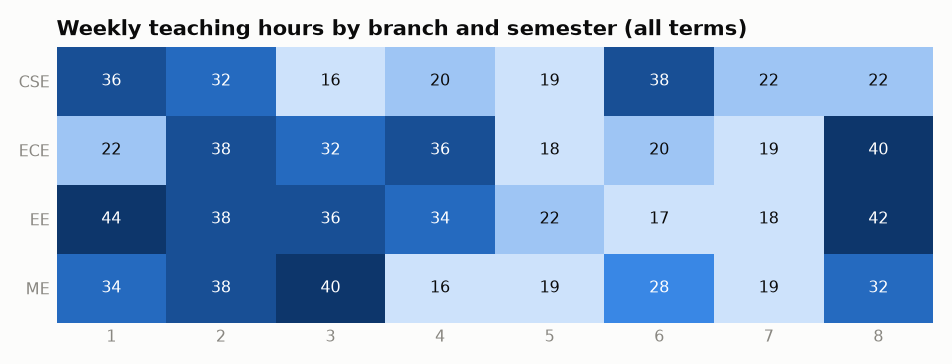

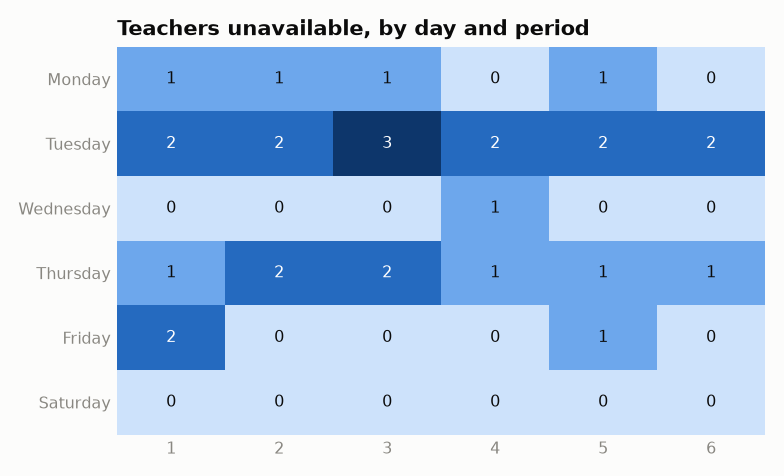

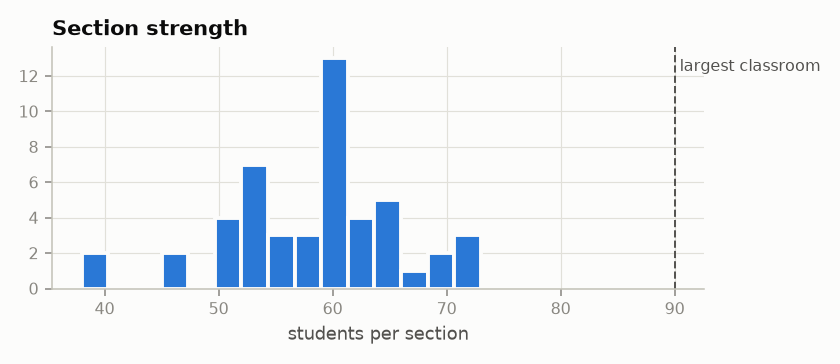

In [5]:
checks, detail = analyze.feasibility(whole)
files = analyze.charts(whole, detail, '../reports/notebook/all', 'all terms')
display(checks)
for f in files: display(Image(str(f)))

## 3. Removal and filtering

Repair what can be fixed, remove what can't, then keep only the odd semesters. Every change is logged.

In [6]:
res = clean(raw, term='odd')
display(res.summary())
score, per, false_alarms = score_cleaning(injected, res.log)
score

,table,action,rule,rows
0,Rooms,removed,missing_required,1
1,Sections,filtered,term=odd branches=all,27
2,Sections,repaired,messy_text,1
3,Sections,repaired,number_as_text,1
4,Sections,repaired,strength_imputed,4
5,Subjects,filtered,term=odd branches=all,94
6,Subjects,removed,duplicate_key,1
7,Subjects,repaired,number_as_text,1
8,TeacherSubjectMap,filtered,section out of scope,158
9,TeacherSubjectMap,removed,duplicate_key,1


{'injected': 18,
 'detected': 18,
 'detection_rate': 1.0,
 'correct_action_rate': 1.0,
 'false_alarms': 0,
 'cascade_removals': 0,
 'hits': 18}

In [7]:
res.log[res.log.action != 'filtered'].head(20)

,table,row,action,rule,detail,cascade
0,Sections,42,repaired,messy_text,BranchCode: ' me ' -> 'ME',False
1,Sections,29,repaired,number_as_text,Strength: '54' -> 54,False
2,Subjects,20,repaired,number_as_text,WeeklyHours: '4 hrs' -> 4,False
3,Teachers,10,repaired,messy_text,TeacherID: ' tt0009 ' -> 'TT0009',False
4,Sections,11,repaired,strength_imputed,Strength 0 -> 59,False
5,Sections,19,repaired,strength_imputed,Strength 0 -> 59,False
6,Sections,27,repaired,strength_imputed,Strength 999 -> 73,False
7,Sections,43,repaired,strength_imputed,Strength 0 -> 59,False
8,Teachers,31,repaired,load_clipped,MaxWeeklyLoad 80 -> 40,False
9,Teachers,40,repaired,load_clipped,MaxWeeklyLoad 80 -> 40,False


## 4. Feasibility gate for the odd term

,check,status,value,limit,note
0,Classroom periods,PASS,350,576,16 classrooms x 36 slots
1,Lab blocks,PASS,33,72,4 labs x 18 two-period starts a week
2,Section fits a classroom,PASS,0,0,largest classroom seats 90
3,Section fits a lab,WARN,9,0,largest lab seats 60; bigger sections need bat...
4,Every class has a teacher,PASS,0,0,section x subject pairs with no teacher
5,Section weekly hours fit the week,PASS,22,36,busiest section
6,Teachers within weekly load,PASS,0,0,teachers assigned more hours than their max
7,Teachers have enough free slots,PASS,0,0,hours > slots left after unavailability
8,Travel time for every block pair,PASS,0,0,complete


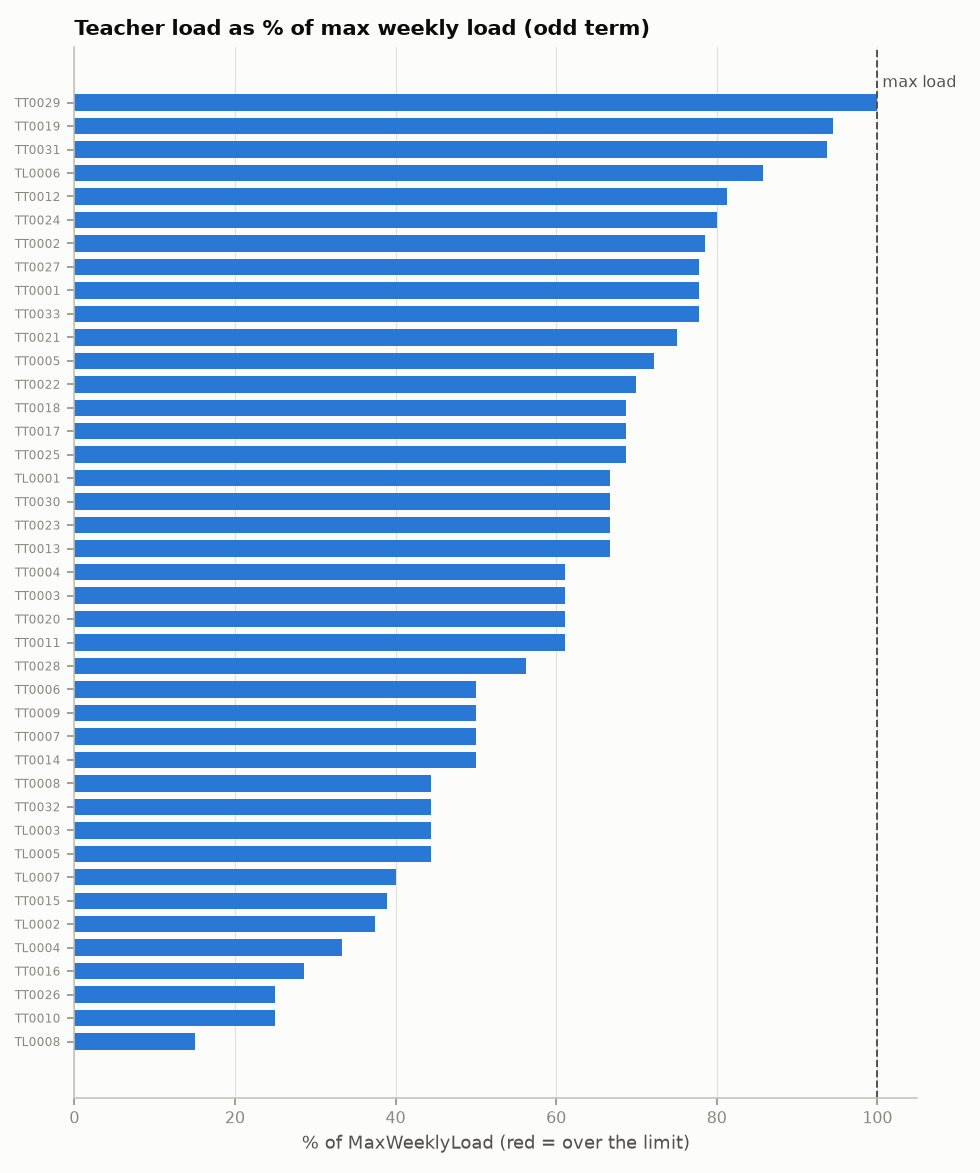

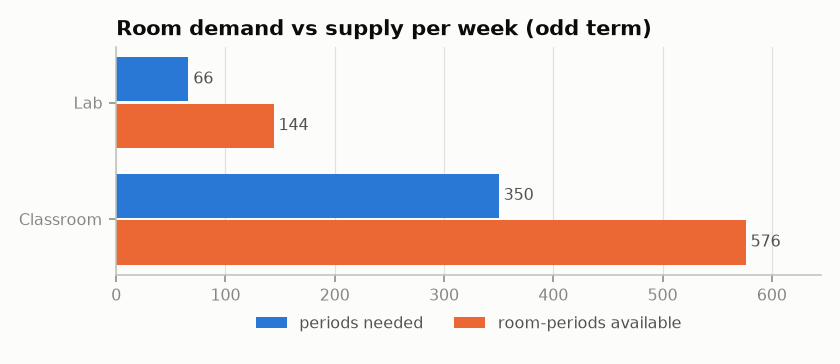

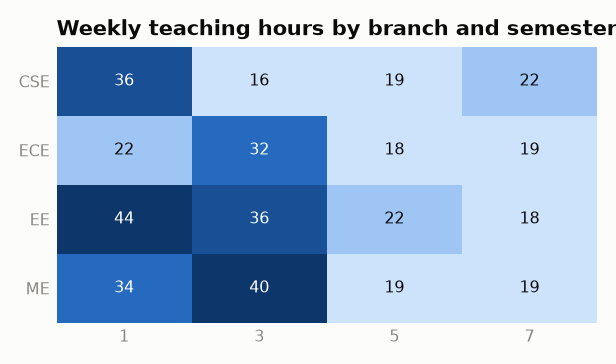

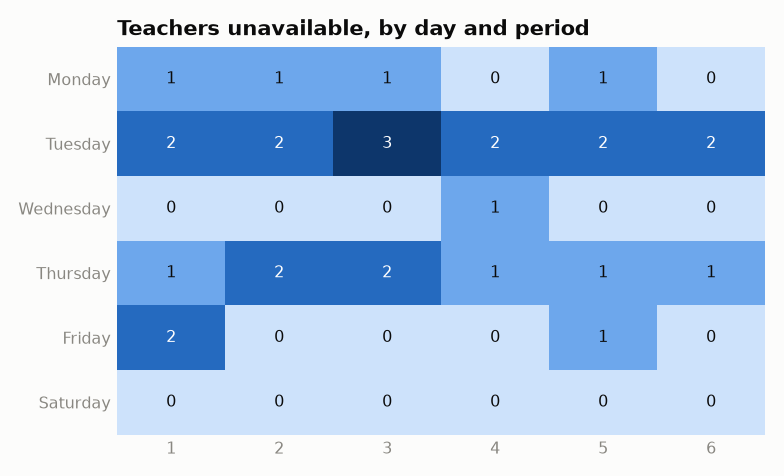

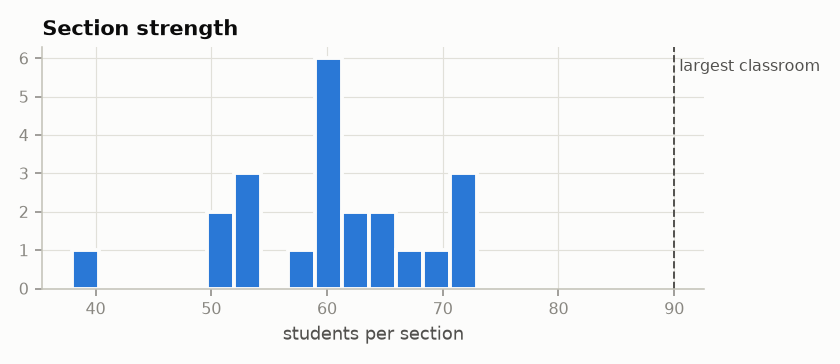

In [8]:
checks, detail = analyze.feasibility(res.data)
files = analyze.charts(res.data, detail, '../reports/notebook/term', 'odd term')
display(checks)
for f in files: display(Image(str(f)))

## 5. Next part: the CP-SAT solver

Google OR-Tools CP-SAT places every session; `verify` re-checks every hard rule without trusting the model.

In [9]:
sol = solve(res.data, time_limit=30)
print(sol.stats)
print('hard-rule violations:', verify(sol.timetable, res.data))
sol.timetable.head(12)

{'status': 'FEASIBLE', 'build_seconds': 0.63, 'solve_seconds': 30.2, 'variables': 33606, 'constraints': 36513, 'sessions': 383, 'unassigned_pairs': 0, 'objective': 484.0, 'best_bound': 78.0, 'soft_blocks': 15, 'soft_spread': 6, 'soft_balance': 7, 'soft_home': 94, 'soft_late': 21, 'soft_unplaced': 0, 'placed_periods': 416, 'unplaced_sessions': 0, 'total_seconds': 31.72}
hard-rule violations: []


,SectionID,Day,Period,SubjectCode,Type,TeacherID,RoomID,Building,Session,Strength,SubjectName
0,CSE-Y1S1-A,Monday,3,CSE101,Theory,TT0006,A104,A,0,64,Basic Electronics
1,CSE-Y1S1-A,Monday,4,CSE103,Theory,TT0005,A106,A,7,64,Communication Skills: Theory and Practices
2,CSE-Y1S1-B,Monday,1,CSE102,Theory,TT0002,A106,A,19,62,Rashtra Gaurav
3,CSE-Y1S1-B,Monday,3,CSE103,Theory,TT0005,A106,A,25,62,Communication Skills: Theory and Practices
4,CSE-Y2S3-A,Monday,1,CSE303,Theory,TT0004,A103,A,41,38,Object Oriented Concepts using Java
5,CSE-Y2S3-A,Monday,5,CSE304,Theory,TT0003,A105,A,44,38,Discrete Structure
6,CSE-Y3S5-A,Monday,3,CSE502,Theory,TT0001,A105,A,51,60,Introduction to Artificial Intelligence
7,CSE-Y3S5-A,Monday,2,CSE503,Theory,TT0005,A106,A,57,60,Cloud Computing
8,CSE-Y3S5-A,Monday,5,CSE504,Theory,TT0004,A104,A,61,60,Full Stack Development- Backend
9,CSE-Y4S7-A,Monday,4,CSE701,Theory,TT0006,A105,A,64,51,Career Development Course


In [10]:
# one section's week as a grid
sec = sol.timetable.SectionID.iloc[0]
g = sol.timetable[sol.timetable.SectionID == sec]
g.assign(cell=g.SubjectCode + ' / ' + g.RoomID).pivot_table(index='Day', columns='Period', values='cell', aggfunc='first').reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday'])

Period,1,2,3,4,5,6
Day,,,,,,
Monday,NaN,NaN,CSE101 / A104,CSE103 / A106,CSE102 / B104,NaN
Tuesday,CSE101 / A106,CSE102 / A106,NaN,NaN,NaN,NaN
Wednesday,CSE1L1 / L101,CSE1L1 / L101,CSE104 / A106,CSE103 / A106,NaN,NaN
Thursday,CSE102 / A104,NaN,NaN,CSE103 / B104,CSE101 / B104,CSE104 / A104
Friday,CSE104 / A103,NaN,CSE1L2 / L101,CSE1L2 / L101,NaN,NaN
Saturday,NaN,NaN,NaN,CSE102 / A103,CSE104 / A101,NaN
